Dataset: Groceries Dataset
Total records: 38765

First five records:
   Member_number        Date   itemDescription
0           1808  21-07-2015    tropical fruit
1           2552  05-01-2015        whole milk
2           2300  19-09-2015         pip fruit
3           1187  12-12-2015  other vegetables
4           3037  01-02-2015        whole milk

Total transactions: 14963
Total unique items: 167

Top 10 Frequently Purchased Items:
itemDescription
whole milk          0.157923
other vegetables    0.122101
rolls/buns          0.110005
soda                0.097106
yogurt              0.085879
root vegetables     0.069572
tropical fruit      0.067767
bottled water       0.060683
sausage             0.060349
citrus fruit        0.053131
dtype: float64


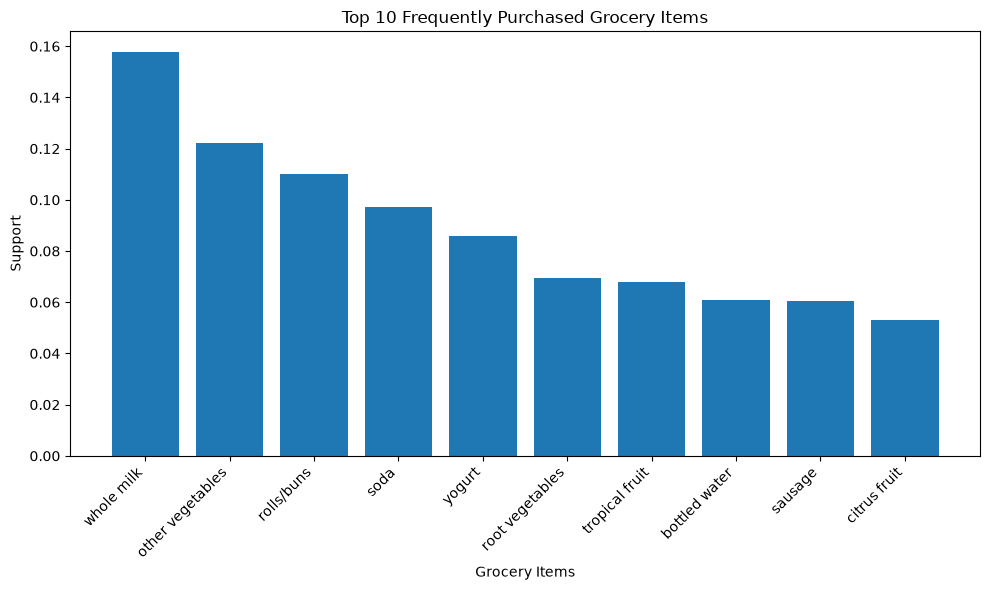


Frequent Itemsets:
    support         itemsets
0  0.021386       (UHT-milk)
1  0.008087  (baking powder)
2  0.033950           (beef)
3  0.021787        (berries)
4  0.016574      (beverages)
5  0.045312   (bottled beer)
6  0.060683  (bottled water)
7  0.037626    (brown bread)
8  0.035220         (butter)
9  0.017577    (butter milk)

No association rules found.
Try reducing min_support or min_threshold.

Conclusion:
Apriori identifies frequently purchased item combinations.
Support measures frequency, confidence measures reliability,
and lift measures the strength of item associations.


In [3]:

# Experiment 11: Association Rule Mining using Apriori Algorithm

import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, association_rules

# 1. Load Dataset
df = pd.read_csv("Groceries_dataset.csv")

print("Dataset: Groceries Dataset")
print("Total records:", len(df))
print("\nFirst five records:")
print(df.head())

# 2. Data Preprocessing
df.dropna(inplace=True)

df.drop_duplicates(
    subset=["Member_number", "Date", "itemDescription"],
    inplace=True
)

# 3. Create Transaction Basket
basket = df.groupby(
    ["Member_number", "Date", "itemDescription"]
).size().unstack(fill_value=0)

# Convert values into Boolean format
basket = basket > 0

print("\nTotal transactions:", len(basket))
print("Total unique items:", len(basket.columns))

# 4. Bar Chart of Top 10 Frequently Purchased Items
item_support = basket.mean().sort_values(
    ascending=False
).head(10)

print("\nTop 10 Frequently Purchased Items:")
print(item_support)

plt.figure(figsize=(10, 6))
plt.bar(item_support.index, item_support.values)
plt.xlabel("Grocery Items")
plt.ylabel("Support")
plt.title("Top 10 Frequently Purchased Grocery Items")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 5. Generate Frequent Itemsets
frequent_items = apriori(
    basket,
    min_support=0.005,
    use_colnames=True
)

print("\nFrequent Itemsets:")
print(frequent_items.head(10))

# 6. Generate Association Rules
if (not frequent_items.empty and
        frequent_items["itemsets"].map(len).max() >= 2):

    rules = association_rules(
        frequent_items,
        metric="confidence",
        min_threshold=0.20
    )

    # Select rules with lift greater than 1
    rules = rules[rules["lift"] > 1]

    if not rules.empty:

        rules = rules.sort_values(
            by="confidence",
            ascending=False
        )

        print("\nTop 10 Association Rules:")
        print(
            rules[
                ["antecedents", "consequents",
                 "support", "confidence", "lift"]
            ].head(10).to_string(index=False)
        )

        # 7. Bar Chart of Top 10 Association Rules
        top_rules = rules.head(10).copy()

        labels = [
            f"{', '.join(a)} -> {', '.join(c)}"
            for a, c in zip(
                top_rules["antecedents"],
                top_rules["consequents"]
            )
        ]

        plt.figure(figsize=(10, 6))
        plt.barh(labels, top_rules["confidence"])
        plt.xlabel("Confidence")
        plt.ylabel("Association Rules")
        plt.title("Top 10 Association Rules")
        plt.gca().invert_yaxis()
        plt.tight_layout()
        plt.show()

        # 8. Save Results
        frequent_items.to_csv(
            "frequent_itemsets.csv", index=False
        )

        rules.to_csv(
            "association_rules.csv", index=False
        )

        print("\nFrequent itemsets saved to frequent_itemsets.csv")
        print("Association rules saved to association_rules.csv")

    else:
        print("\nNo association rules found.")
        print("Try reducing min_support or min_threshold.")

else:
    print("\nNo frequent itemsets containing multiple items.")
    print("Try reducing min_support.")
